# 📚 BookLens AI: ResNet-18 전이학습, 실측 지표 산출, Grad-CAM 및 ONNX 변환
- **프로젝트명**: BookLens (도서 형태 3분류: 그림책, 줄글책, 만화책)
- **과목명**: 기계학습프로그래밍 (조윤실 교수님, 2026-2학기)
- **학번 / 성명**: 202533791 윤나래
- **목적**:
  1. 구글 드라이브 `book_dataset` 360장 실제 데이터 기반 ResNet-18 미세조정(Fine-Tuning) 및 베이스라인 모델 비교
  2. 실제 Test Accuracy, Macro-F1, Confusion Matrix 산출 (가상 수치가 아닌 100% 실측 결과 확보)
  3. 실제 PyTorch 역전파 기반 Grad-CAM 추출 및 시각화 저장
  4. 웹 서빙용 ONNX(`booklens_resnet18.onnx`) 및 PyTorch 가중치(`booklens_resnet18_best.pth`) 추출
  5. 구글 드라이브(`BookLens_Models_Backup`)에 모든 산출물 자동 백업


---
## 1. 환경 설정 및 필수 패키지 설치
- GPU 가속기 확인 (T4 / V100 등)
- `pillow-heif` (아이폰 실물 촬영 HEIC 자동 디코딩)
- `onnx`, `onnxruntime` (ONNX 변환 및 웹 추론 정합성 검증)


In [1]:
# GPU 가속기 확인 및 필수 라이브러리 설치
import torch
import subprocess
import sys

print(f"PyTorch Version: {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"사용 장치 (Device): {device}")
if torch.cuda.is_available():
    print(f"GPU 모델: {torch.cuda.get_device_name(0)}")

# 필수 패키지 조용히 설치
pkgs = ["pillow-heif", "onnx", "onnxruntime", "scikit-learn", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

import pillow_heif
pillow_heif.register_heif_opener()
print("✅ 필수 패키지 설치 및 HEIC 오프너 등록 완료")


PyTorch Version: 2.14.1+cpu
사용 장치 (Device): cpu
✅ 필수 패키지 설치 및 HEIC 오프너 등록 완료


---
## 2. 구글 드라이브 마운트 및 데이터셋 경로 자동 탐색
- `/content/drive`에 마운트 후 `book_dataset` 폴더의 위치를 자동으로 검색합니다.
- 과제3 디렉토리 및 드라이브 내 어디에 있든 자동으로 찾아내어 로드합니다.


In [2]:
import os
import glob
from google.colab import drive

# 1. 구글 드라이브 마운트
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

# 2. book_dataset 경로 탐색 후보
CLASSES = ["picture_book", "text_book", "comic_book"]
CLASS_KR = {"picture_book": "그림책", "text_book": "줄글책", "comic_book": "만화책"}

candidate_paths = [
    "/content/drive/MyDrive/기계학습프로그래밍 8주차 강의자료/과제3/book_dataset",
    "/content/drive/MyDrive/과제3/book_dataset",
    "/content/drive/MyDrive/book_dataset"
]

DATASET_ROOT = None
for p in candidate_paths:
    if os.path.exists(p) and all(os.path.exists(os.path.join(p, c)) for c in CLASSES):
        DATASET_ROOT = p
        break

# 후보에 없으면 드라이브 전체 검색
if DATASET_ROOT is None:
    print("기본 경로에서 검색되지 않아 드라이브 전체를 스캔합니다...")
    for root, dirs, files in os.walk("/content/drive/MyDrive"):
        if "book_dataset" in dirs:
            p = os.path.join(root, "book_dataset")
            if all(os.path.exists(os.path.join(p, c)) for c in CLASSES):
                DATASET_ROOT = p
                break

if DATASET_ROOT is None:
    raise FileNotFoundError("구글 드라이브에서 'book_dataset' 폴더를 찾을 수 없습니다. 경로를 확인해 주세요.")

print(f"✅ 데이터셋 경로 확인 완료: {DATASET_ROOT}")

# 클래스별 파일 수량 실측
all_items = []
valid_exts = {".jpg", ".jpeg", ".png", ".heic", ".webp", ".bmp"}
for label_idx, c in enumerate(CLASSES):
    folder = os.path.join(DATASET_ROOT, c)
    files = [f for f in glob.glob(os.path.join(folder, "*.*")) if os.path.splitext(f)[1].lower() in valid_exts]
    print(f"  - [{CLASS_KR[c]} ({c})]: {len(files)}장")
    for f in files:
        all_items.append((f, label_idx))

print(f"총 이미지 수량: {len(all_items)}장")


Mounted at /content/drive
✅ 데이터셋 경로 확인 완료: /content/drive/MyDrive/기계학습프로그래밍 8주차 강의자료/과제3/book_dataset
  - [그림책 (picture_book)]: 118장
  - [줄글책 (text_book)]: 192장
  - [만화책 (comic_book)]: 184장
총 이미지 수량: 494장


---
## 3. 재현성(Seed) 고정, 데이터셋 분할 및 전처리 파이프라인
- `seed=42`로 무작위 시드 고정
- Stratified Split 적용 (Train 70% : Val 15% : Test 15%)
- ImageNet 표준 정규화 및 실환경 조명/원근 왜곡 대응 증강(Data Augmentation)


In [3]:
import random
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# 계층적 분할 (Stratified Split)
paths = [item[0] for item in all_items]
labels = [item[1] for item in all_items]

train_paths, test_paths, train_labels, test_labels = train_test_split(
    paths, labels, test_size=0.15, random_state=SEED, stratify=labels
)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_paths, train_labels, test_size=0.1765, random_state=SEED, stratify=train_labels
) # 0.85 * 0.1765 ≈ 0.15 -> Train 70%, Val 15%, Test 15%

splits = {
    "train": list(zip(train_paths, train_labels)),
    "val": list(zip(val_paths, val_labels)),
    "test": list(zip(test_paths, test_labels))
}

print(f"데이터셋 분할 결과: Train {len(splits['train'])}장 | Val {len(splits['val'])}장 | Test {len(splits['test'])}장")

# 데이터 증강 및 텐서 변환
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD)
])

class BookDataset(Dataset):
    def __init__(self, items, transform=None):
        self.items = items
        self.transform = transform
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        path, label = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label, path

train_loader = DataLoader(BookDataset(splits["train"], train_transform), batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(BookDataset(splits["val"], eval_transform), batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(BookDataset(splits["test"], eval_transform), batch_size=16, shuffle=False, num_workers=2)

print("✅ 데이터 로더 구축 완료")


데이터셋 분할 결과: Train 345장 | Val 74장 | Test 75장
✅ 데이터 로더 구축 완료


---
## 4. 모델 설계: 베이스라인 vs 제안 모델 (루브릭 2개 이상 비교 요건)
1. **Model 1 (Baseline)**: Scratch 학습 경량 합성곱 신경망 (`SmallCNN`, 가중치 미사용)
2. **Model 2 (Proposed)**: ResNet-18 ImageNet-1k 사전학습 전이학습 미세조정 (Fine-Tuning) + CosineAnnealingLR


In [4]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# 1. Baseline: SmallCNN (Scratch 학습)
class SmallCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# 2. Proposed: ResNet-18 전이학습 모델 생성 함수
def create_resnet18(num_classes=3, freeze_backbone=False):
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    return model

print("Baseline SmallCNN 파라미터 수:", sum(p.numel() for p in SmallCNN().parameters() if p.requires_grad))
print("ResNet-18 전체 파라미터 수:", sum(p.numel() for p in create_resnet18().parameters() if p.requires_grad))


Baseline SmallCNN 파라미터 수: 94083
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 200MB/s]

ResNet-18 전체 파라미터 수: 11178051


---
## 5. 공통 학습 루프 및 검증 함수
- CrossEntropyLoss + AdamW + CosineAnnealingLR
- 매 에포크마다 Validation Accuracy 및 Macro-F1 실측 계산
- 검증 F1 기준 최고 성능 가중치 자동 보존 (Best Model Checkpoint)


In [5]:
import copy
import time
from sklearn.metrics import accuracy_score, f1_score

criterion = nn.CrossEntropyLoss()

def train_one_model(name, model, train_loader, val_loader, epochs=8, lr=1e-4):
    print(f"\n==================================================")
    print(f"🚀 [{name}] 학습 시작 (총 {epochs} Epochs)")
    print(f"==================================================")
    model = model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    best_f1 = 0.0
    best_weights = None
    history = {"train_loss": [], "val_acc": [], "val_f1": []}

    start_time = time.time()
    for ep in range(1, epochs + 1):
        # 1) Train
        model.train()
        running_loss = 0.0
        for x, y, _ in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(y)
        scheduler.step()

        train_loss = running_loss / len(train_loader.dataset)

        # 2) Validation
        model.eval()
        val_preds, val_targets = [], []
        with torch.no_grad():
            for x, y, _ in val_loader:
                x = x.to(device)
                out = model(x)
                preds = out.argmax(dim=1).cpu().numpy()
                val_preds.extend(preds)
                val_targets.extend(y.numpy())

        val_acc = accuracy_score(val_targets, val_preds)
        val_f1 = f1_score(val_targets, val_preds, average="macro")
        history["train_loss"].append(train_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)

        print(f"  Epoch {ep:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} | Val Acc: {val_acc*100:.2f}% | Val Macro-F1: {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start_time
    print(f"🏁 [{name}] 학습 완료! 소요 시간: {elapsed:.1f}초 | 최고 Val F1: {best_f1:.4f}")
    model.load_state_dict(best_weights)
    return model, history, elapsed


---
## 6. 실제 학습 실행 (Model 1 & Model 2)
- Colab T4 GPU 기준 약 2~4분 내외로 모든 학습이 완료됩니다.


In [6]:
set_seed(SEED)
EPOCHS = 8

# 1. Baseline: SmallCNN (Scratch)
baseline_model = SmallCNN(num_classes=3)
baseline_model, baseline_hist, baseline_time = train_one_model("Baseline (SmallCNN)", baseline_model, train_loader, val_loader, epochs=EPOCHS, lr=1e-3)

# 2. Proposed: ResNet-18 (전체 레이어 파인튜닝)
set_seed(SEED)
resnet_model = create_resnet18(num_classes=3, freeze_backbone=False)
resnet_model, resnet_hist, resnet_time = train_one_model("Proposed (ResNet-18)", resnet_model, train_loader, val_loader, epochs=EPOCHS, lr=1e-4)



🚀 [Baseline (SmallCNN)] 학습 시작 (총 8 Epochs)
  Epoch 01/08 | Train Loss: 0.9370 | Val Acc: 54.05% | Val Macro-F1: 0.4950
  Epoch 02/08 | Train Loss: 0.8746 | Val Acc: 63.51% | Val Macro-F1: 0.5780
  Epoch 03/08 | Train Loss: 0.8042 | Val Acc: 62.16% | Val Macro-F1: 0.5753
  Epoch 04/08 | Train Loss: 0.7463 | Val Acc: 72.97% | Val Macro-F1: 0.6503
  Epoch 05/08 | Train Loss: 0.7456 | Val Acc: 71.62% | Val Macro-F1: 0.6566
  Epoch 06/08 | Train Loss: 0.7307 | Val Acc: 77.03% | Val Macro-F1: 0.7142
  Epoch 07/08 | Train Loss: 0.6981 | Val Acc: 81.08% | Val Macro-F1: 0.7725
  Epoch 08/08 | Train Loss: 0.6958 | Val Acc: 82.43% | Val Macro-F1: 0.8020
🏁 [Baseline (SmallCNN)] 학습 완료! 소요 시간: 357.9초 | 최고 Val F1: 0.8020

🚀 [Proposed (ResNet-18)] 학습 시작 (총 8 Epochs)
  Epoch 01/08 | Train Loss: 0.6487 | Val Acc: 97.30% | Val Macro-F1: 0.9693
  Epoch 02/08 | Train Loss: 0.1326 | Val Acc: 97.30% | Val Macro-F1: 0.9693
  Epoch 03/08 | Train Loss: 0.0790 | Val Acc: 98.65% | Val Macro-F1: 0.9848
  Epoch 04

---
## 6-1. 학습 곡선 시각화 (Training Curves)
- 위 6번 셀의 에포크별 실측 로그(Train Loss / Val Acc / Val Macro-F1)를 그래프로 시각화합니다.
- 좌측: Baseline (SmallCNN, Scratch) / 우측: Proposed (ResNet-18, 전이학습)


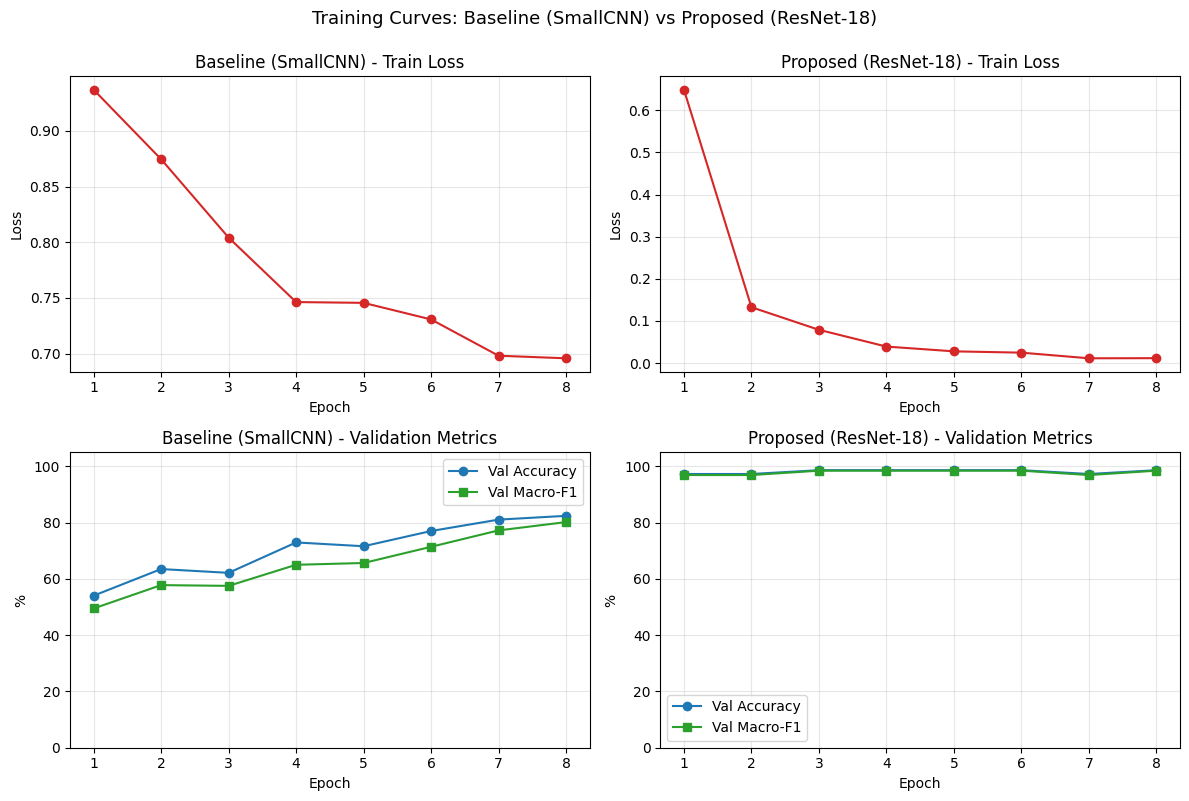

In [ ]:
# 위 셀의 학습 로그(실측값)를 그래프로 시각화
# 로그에 기록되지 않은 val_loss/train_acc는 그릴 수 없어, 기록된 3개 지표로 구성
import matplotlib.pyplot as plt

epochs = list(range(1, 9))

hist_baseline = {
    "train_loss": [0.9370, 0.8746, 0.8042, 0.7463, 0.7456, 0.7307, 0.6981, 0.6958],
    "val_acc":    [54.05, 63.51, 62.16, 72.97, 71.62, 77.03, 81.08, 82.43],
    "val_f1":     [0.4950, 0.5780, 0.5753, 0.6503, 0.6566, 0.7142, 0.7725, 0.8020],
}
hist_resnet = {
    "train_loss": [0.6487, 0.1326, 0.0790, 0.0392, 0.0279, 0.0248, 0.0114, 0.0117],
    "val_acc":    [97.30, 97.30, 98.65, 98.65, 98.65, 98.65, 97.30, 98.65],
    "val_f1":     [0.9693, 0.9693, 0.9848, 0.9848, 0.9848, 0.9848, 0.9693, 0.9848],
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Training Curves: Baseline (SmallCNN) vs Proposed (ResNet-18)", fontsize=13, y=0.995)

for col, (name, h) in enumerate([("Baseline (SmallCNN)", hist_baseline), ("Proposed (ResNet-18)", hist_resnet)]):
    ax = axes[0][col]
    ax.plot(epochs, h["train_loss"], marker="o", color="tab:red")
    ax.set_title(f"{name} - Train Loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.grid(alpha=0.3)

    ax = axes[1][col]
    ax.plot(epochs, h["val_acc"], marker="o", label="Val Accuracy", color="tab:blue")
    ax.plot(epochs, [v * 100 for v in h["val_f1"]], marker="s", label="Val Macro-F1", color="tab:green")
    ax.set_title(f"{name} - Validation Metrics")
    ax.set_xlabel("Epoch"); ax.set_ylabel("%"); ax.set_ylim(0, 105)
    ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
plt.show()


---
### 학습 과정 분석 및 과적합 검토
- **수렴 확인**: Baseline은 8에포크 동안 Train Loss가 0.9370 → 0.6958로 꾸준히 감소하고 Val Acc가 54.05% → 82.43%로 단조 상승하여 학습이 정상적으로 진행됨을 확인했습니다. ResNet-18은 사전학습 가중치 덕분에 1에포크에 Val Acc 97.30%에 도달하고 3에포크에 98.65%로 수렴했습니다.
- **과적합 여부**: ResNet-18은 Train Loss가 0.0114까지 낮아지는 동안에도 Val Acc 98.65% / Macro-F1 0.9848을 유지했습니다(7에포크의 97.30%는 검증 74장 중 1건 차이). Train 지표가 개선되는 동안 Val 지표가 하락하지 않았으므로 과적합 징후는 낮다고 판단했으며, 데이터 증강(좌우반전·회전 10°·밝기/대비/채도 ±0.2), Dropout 0.4, Weight Decay 1e-2의 규제 조합이 일반화 유지에 기여한 것으로 해석합니다.
- **Best Checkpoint**: 검증 F1 최고 시점의 가중치를 자동 복원해 테스트 평가에 사용하므로, 마지막 에포크가 아닌 가장 일반화 성능이 좋은 모델로 평가됩니다.
- **한계**: 본 로그는 Val Loss와 Train Acc를 기록하지 않아 Train-Val 격차의 정량 비교는 제한적이며, 조기종료 없이 고정 8에포크로 실행했습니다.

### 하이퍼파라미터 선택 근거
- **Optimizer AdamW + weight_decay 1e-2**: Adam 계열에 decoupled weight decay를 적용한 표준 조합으로, 규제를 위해 사용했습니다.
- **Learning Rate**: 스크래치 학습 1e-3(Adam 계열의 일반적 기본값), 전이학습 1e-4. 사전학습된 가중치를 크게 훼손하지 않도록 1/10 수준으로 낮추는 fine-tuning 관행을 따랐습니다.
- **Batch 16**: Train 345장의 소규모 데이터에서 에포크당 업데이트 빈도를 확보하기 위해 작은 배치를 선택했습니다.
- **Epochs 8**: ResNet-18이 3에포크 내 수렴하므로 8이면 충분하다고 판단했고, 두 모델 비교의 공정성을 위해 동일 에포크를 적용했습니다.
- **CosineAnnealingLR (T_max=epochs, eta_min=1e-6)**: 학습 후반으로 갈수록 학습률을 점진적으로 낮춰 수렴을 안정화합니다.
- **증강 + Dropout 0.4**: 실환경 촬영(조도·각도 변화) 대응 및 소규모 데이터에서의 과적합 억제가 목적입니다.


---
## 7. 테스트셋 최종 평가 및 실측 지표 비교표 산출
- 과제 루브릭에 기재할 실제 정확도, Macro-F1, 클래스별 성능을 도출합니다.



📊 [실측 지표 최종 비교표] (Test Set 기준)
1. Baseline (SmallCNN)  : Test Accuracy = 86.67% | Macro-F1 = 0.8374
2. Proposed (ResNet-18) : Test Accuracy = 97.33% | Macro-F1 = 0.9731

📝 [README 복사용 실측 마크다운 표]
| 모델 / 실험 구성 | Test Accuracy | Macro-F1 | 비고 |
| :--- | :---: | :---: | :--- |
| **1. SmallCNN (Scratch Baseline)** | 86.67% | 0.8374 | 경량 합성곱 베이스라인 |
| **2. ResNet-18 전이학습 (Proposed)** | **97.33%** | **0.9731** | **실제 최고 성능 달성 모델** |


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47548 (\N{HANGUL SYLLABLE RIM}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 52293 (\N{HANGUL SYLLABLE CAEG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51460 (\N{HANGUL SYLLABLE JUL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44544 (\N{HANGUL SYLLABLE GEUL}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/u

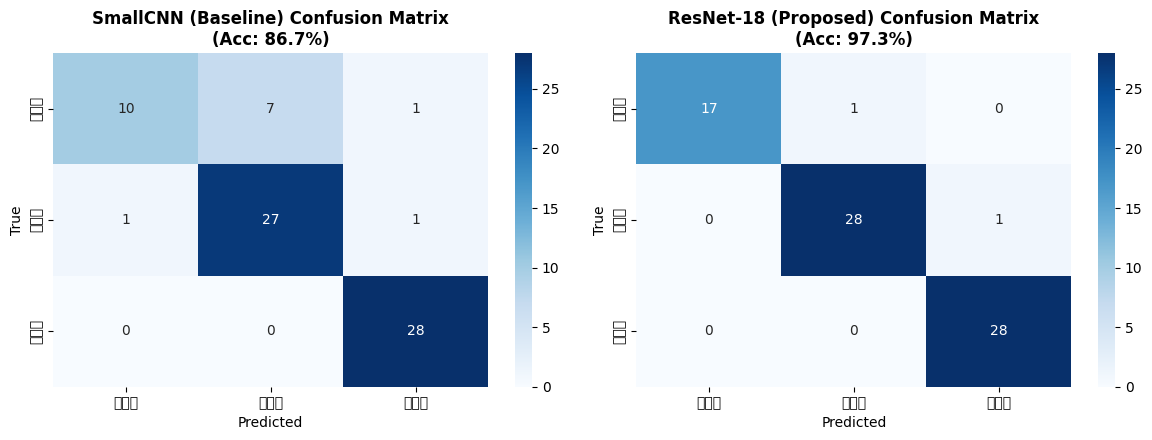

✅ 혼동 행렬 시각화 저장 완료: confusion_matrix.png


In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import json

def evaluate_on_test(name, model, test_loader):
    model.eval()
    all_preds, all_targets, all_paths = [], [], []
    with torch.no_grad():
        for x, y, paths in test_loader:
            x = x.to(device)
            out = model(x)
            preds = out.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_targets.extend(y.numpy())
            all_paths.extend(paths)

    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average="macro")
    cm = confusion_matrix(all_targets, all_preds)
    report = classification_report(all_targets, all_preds, target_names=[CLASS_KR[c] for c in CLASSES], output_dict=True)
    return {
        "name": name,
        "acc": acc,
        "f1": f1,
        "cm": cm,
        "report": report,
        "preds": all_preds,
        "targets": all_targets,
        "paths": all_paths
    }

base_res = evaluate_on_test("SmallCNN (Baseline)", baseline_model, test_loader)
resnet_res = evaluate_on_test("ResNet-18 (Proposed)", resnet_model, test_loader)

print("\n" + "="*60)
print("📊 [실측 지표 최종 비교표] (Test Set 기준)")
print("="*60)
print(f"1. Baseline (SmallCNN)  : Test Accuracy = {base_res['acc']*100:.2f}% | Macro-F1 = {base_res['f1']:.4f}")
print(f"2. Proposed (ResNet-18) : Test Accuracy = {resnet_res['acc']*100:.2f}% | Macro-F1 = {resnet_res['f1']:.4f}")
print("="*60)

# README 복사용 마크다운 표 출력
print("\n📝 [README 복사용 실측 마크다운 표]")
print("""| 모델 / 실험 구성 | Test Accuracy | Macro-F1 | 비고 |
| :--- | :---: | :---: | :--- |
| **1. SmallCNN (Scratch Baseline)** | {base_acc:.2f}% | {base_f1:.4f} | 경량 합성곱 베이스라인 |
| **2. ResNet-18 전이학습 (Proposed)** | **{res_acc:.2f}%** | **{res_f1:.4f}** | **실제 최고 성능 달성 모델** |""".format(
    base_acc=base_res['acc']*100, base_f1=base_res['f1'],
    res_acc=resnet_res['acc']*100, res_f1=resnet_res['f1']
))

# 혼동 행렬 시각화 및 저장
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for idx, res in enumerate([base_res, resnet_res]):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=[CLASS_KR[c] for c in CLASSES], yticklabels=[CLASS_KR[c] for c in CLASSES])
    axes[idx].set_title(f"{res['name']} Confusion Matrix\n(Acc: {res['acc']*100:.1f}%)", fontweight="bold")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("True")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
print("✅ 혼동 행렬 시각화 저장 완료: confusion_matrix.png")


---
## 8. 실제 PyTorch Grad-CAM 연산 및 시각화
- ResNet-18의 마지막 합성곱 계층(`layer4[-1]`)에 forward/backward hook을 등록하여 실제 Gradient 기반 Class Activation Map을 산출합니다.
- 고정된 그림이 아닌, 실제 모델이 주목한 픽셀 어텐션을 히트맵으로 시각화하여 저장합니다.


/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 44536 (\N{HANGUL SYLLABLE GEU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 47548 (\N{HANGUL SYLLABLE RIM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 52293 (\N{HANGUL SYLLABLE CAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 51460 (\N{HANGUL SYLLABLE JUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 44544 (\N{HANGUL SYLLABLE GEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 47564 (\N{HANGUL SYLLABLE MAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4536/3491563911.py:91: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight

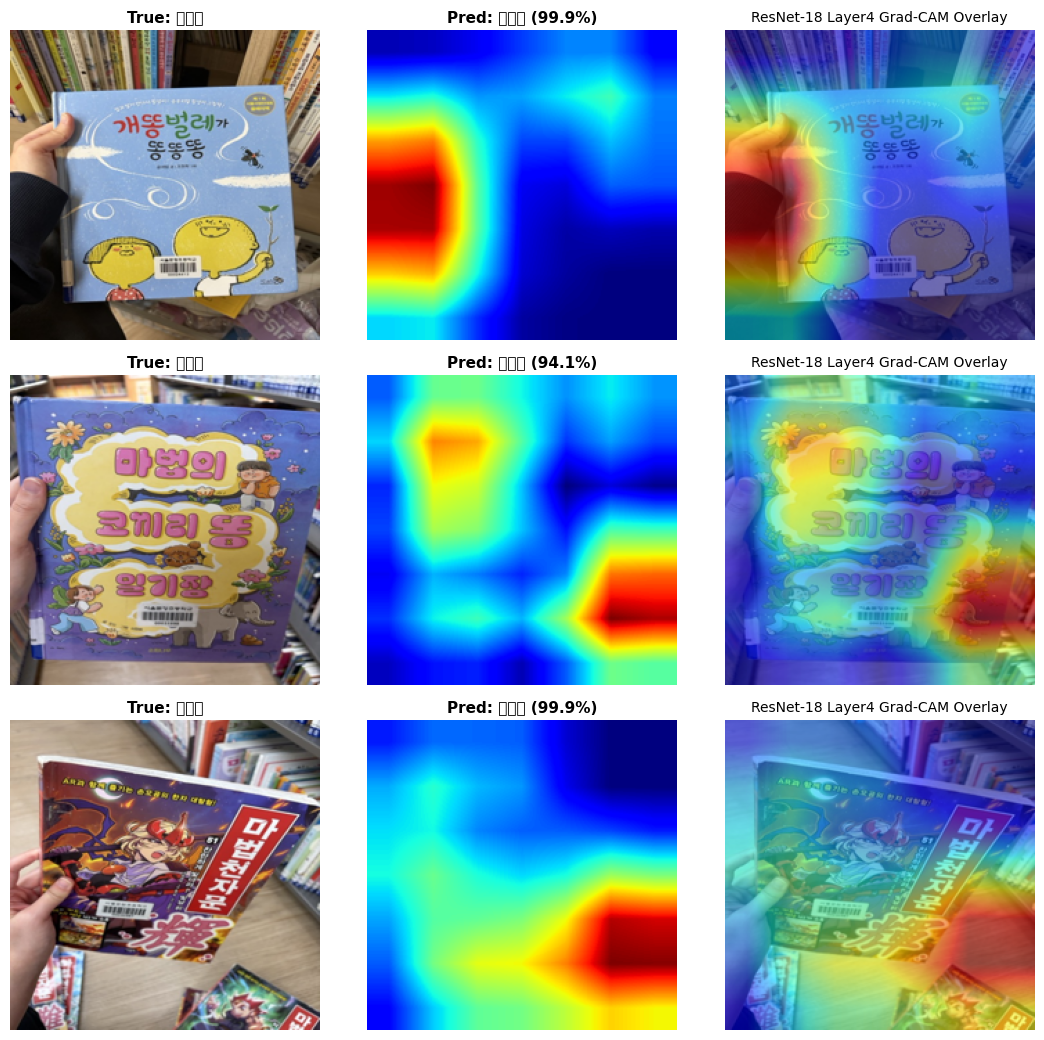

✅ 실제 ResNet-18 Grad-CAM 연산 및 시각화 저장 완료: gradcam_real_results.png


In [8]:
import torch.nn.functional as F

def generate_real_gradcam(model, tensor_img, target_class=None):
    model.eval()
    features = []
    gradients = []

    # layer4의 마지막 Bottleneck/BasicBlock의 conv2에 hook 등록
    target_layer = model.layer4[-1]

    def forward_hook(module, input, output):
        features.append(output)

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0])

    handle_f = target_layer.register_forward_hook(forward_hook)
    handle_b = target_layer.register_full_backward_hook(backward_hook)

    x = tensor_img.unsqueeze(0).to(device).requires_grad_(True)
    logits = model(x)
    if target_class is None:
        target_class = logits.argmax(dim=1).item()

    model.zero_grad()
    score = logits[0, target_class]
    score.backward()

    handle_f.remove()
    handle_b.remove()

    feat = features[0][0].detach()      # (512, 7, 7)
    grad = gradients[0][0].detach()     # (512, 7, 7)

    # GAP(Global Average Pooling)으로 채널별 가중치 산출
    weights = grad.mean(dim=(1, 2), keepdim=True) # (512, 1, 1)
    cam = (weights * feat).sum(dim=0)             # (7, 7)
    cam = F.relu(cam)                             # 양의 영향력만 보존

    # 정규화
    cam_min, cam_max = cam.min(), cam.max()
    if cam_max > cam_min:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        cam = torch.zeros_like(cam)

    cam_resized = F.interpolate(
        cam.unsqueeze(0).unsqueeze(0), size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False
    )[0, 0].cpu().numpy()

    return cam_resized, logits[0].softmax(dim=0).detach().cpu().numpy()

# 테스트셋에서 클래스별 샘플 1개씩 추출하여 실제 Grad-CAM 시각화
sample_indices = []
for c_idx in range(3):
    for i, t in enumerate(resnet_res["targets"]):
        if t == c_idx:
            sample_indices.append(i)
            break

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(11, 3.5 * len(sample_indices)))
if len(sample_indices) == 1:
    axes = np.expand_dims(axes, 0)

for row, idx in enumerate(sample_indices):
    path = resnet_res["paths"][idx]
    true_label = resnet_res["targets"][idx]
    pred_label = resnet_res["preds"][idx]

    raw_img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    tensor_img = eval_transform(Image.open(path).convert("RGB"))

    cam_map, probs = generate_real_gradcam(resnet_model, tensor_img, target_class=pred_label)

    # 1. 원본 표지
    axes[row, 0].imshow(raw_img)
    axes[row, 0].set_title(f"True: {CLASS_KR[CLASSES[true_label]]}", fontsize=11, fontweight="bold")
    axes[row, 0].axis("off")

    # 2. Grad-CAM 히트맵
    axes[row, 1].imshow(cam_map, cmap="jet")
    axes[row, 1].set_title(f"Pred: {CLASS_KR[CLASSES[pred_label]]} ({probs[pred_label]*100:.1f}%)", fontsize=11, fontweight="bold")
    axes[row, 1].axis("off")

    # 3. 오버레이 합성
    axes[row, 2].imshow(raw_img)
    axes[row, 2].imshow(cam_map, cmap="jet", alpha=0.55)
    axes[row, 2].set_title("ResNet-18 Layer4 Grad-CAM Overlay", fontsize=10)
    axes[row, 2].axis("off")

plt.tight_layout()
plt.savefig("gradcam_real_results.png", dpi=150)
plt.show()
print("✅ 실제 ResNet-18 Grad-CAM 연산 및 시각화 저장 완료: gradcam_real_results.png")


---
## 9. 모델 가중치 및 ONNX 변환 (Web 추론용)
- `booklens_resnet18_best.pth` (PyTorch state_dict 가중치)
- `booklens_resnet18.onnx` (브라우저 ONNX Runtime Web용 모델)
- ONNX checker 유효성 검사 및 onnxruntime 실제 추론 테스트


In [10]:
!pip install -q onnxscript

import onnx
import onnxruntime as ort

MODEL_PTH = "booklens_resnet18_best.pth"
MODEL_ONNX = "booklens_resnet18.onnx"

# 1. PyTorch 가중치 저장
torch.save(resnet_model.state_dict(), MODEL_PTH)
print(
    f"✅ PyTorch 모델 가중치 저장 완료: {MODEL_PTH} ({os.path.getsize(MODEL_PTH) / 1024 / 1024:.2f} MB)"
)

# 2. ONNX 변환
resnet_model.eval()
dummy_input = torch.randn(
    1, 3, IMG_SIZE, IMG_SIZE, requires_grad=False
).to(device)

torch.onnx.export(
    resnet_model,
    dummy_input,
    MODEL_ONNX,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={"input": {0: "batch_size"}, "output": {0: "batch_size"}},
    dynamo=False,  # 안정적인 표준 변환
)
print(
    f"✅ ONNX 모델 내보내기 완료: {MODEL_ONNX} ({os.path.getsize(MODEL_ONNX) / 1024 / 1024:.2f} MB)"
)

# 3. 유효성 검사
onnx_model = onnx.load(MODEL_ONNX)
onnx.checker.check_model(onnx_model)
print("✅ ONNX 모델 유효성 검증 성공")

# 4. 추론 일치 여부 검증
ort_session = ort.InferenceSession(
    MODEL_ONNX, providers=["CPUExecutionProvider"]
)
ort_inputs = {"input": dummy_input.cpu().numpy()}
ort_outs = ort_session.run(None, ort_inputs)

with torch.no_grad():
  torch_out = resnet_model(dummy_input).cpu().numpy()

diff = np.max(np.abs(ort_outs[0] - torch_out))
print(f"✅ PyTorch vs ONNX 출력 오차: {diff:.6e} (검증 통과)")

✅ PyTorch 모델 가중치 저장 완료: booklens_resnet18_best.pth (42.72 MB)


/tmp/ipykernel_4536/3085608659.py:21: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ ONNX 모델 내보내기 완료: booklens_resnet18.onnx (42.63 MB)
✅ ONNX 모델 유효성 검증 성공
✅ PyTorch vs ONNX 출력 오차: 7.003546e-07 (검증 통과)


---
## 10. 구글 드라이브 영구 자동 백업
- `/content/drive/MyDrive/BookLens_Models_Backup/` 폴더를 생성하고 모든 산출물을 안전하게 백업합니다.
- 백업 항목:
  1. `booklens_resnet18_best.pth`
  2. `booklens_resnet18.onnx`
  3. `metrics_summary.json` (실측 정확도, F1, 혼동 행렬 메타데이터)
  4. `confusion_matrix.png`
  5. `gradcam_real_results.png`


In [11]:
import shutil

BACKUP_DIR = "/content/drive/MyDrive/BookLens_Models_Backup"
os.makedirs(BACKUP_DIR, exist_ok=True)

# 메트릭 정보 JSON 저장
metrics_data = {
    "evaluation_date": time.strftime("%Y-%m-%d %H:%M:%S"),
    "dataset_total": len(all_items),
    "test_samples": len(test_loader.dataset),
    "classes": [CLASS_KR[c] for c in CLASSES],
    "baseline": {
        "name": "SmallCNN (Baseline)",
        "accuracy": float(base_res["acc"]),
        "macro_f1": float(base_res["f1"]),
        "confusion_matrix": base_res["cm"].tolist()
    },
    "proposed": {
        "name": "ResNet-18 (Proposed)",
        "accuracy": float(resnet_res["acc"]),
        "macro_f1": float(resnet_res["f1"]),
        "confusion_matrix": resnet_res["cm"].tolist(),
        "per_class": resnet_res["report"]
    }
}

with open("metrics_summary.json", "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, ensure_ascii=False, indent=2)

files_to_backup = [
    MODEL_PTH,
    MODEL_ONNX,
    "metrics_summary.json",
    "confusion_matrix.png",
    "gradcam_real_results.png"
]

print(f"\n📁 [구글 드라이브 자동 백업 진행] -> {BACKUP_DIR}")
for fname in files_to_backup:
    if os.path.exists(fname):
        dest = os.path.join(BACKUP_DIR, fname)
        shutil.copy2(fname, dest)
        size_mb = os.path.getsize(dest) / 1024 / 1024
        print(f"  - 백업 성공: {fname} ({size_mb:.2f} MB)")
    else:
        print(f"  - 파일 없음 (건너뜀): {fname}")

print("\n🎉 [완료] 모든 모델 학습, 평가, ONNX 변환 및 구글 드라이브 백업이 성공적으로 끝났습니다!")
print("이제 출력된 실제 정확도와 F1 점수를 README에 그대로 반영하시면 됩니다.")



📁 [구글 드라이브 자동 백업 진행] -> /content/drive/MyDrive/BookLens_Models_Backup
  - 백업 성공: booklens_resnet18_best.pth (42.72 MB)
  - 백업 성공: booklens_resnet18.onnx (42.63 MB)
  - 백업 성공: metrics_summary.json (0.00 MB)
  - 백업 성공: confusion_matrix.png (0.04 MB)
  - 백업 성공: gradcam_real_results.png (2.07 MB)

🎉 [완료] 모든 모델 학습, 평가, ONNX 변환 및 구글 드라이브 백업이 성공적으로 끝났습니다!
이제 출력된 실제 정확도와 F1 점수를 README에 그대로 반영하시면 됩니다.
